In [3]:
from tensorflow.keras.datasets import mnist

(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)

11490434/11490434 [==============================] - 3s 0us/step
Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)


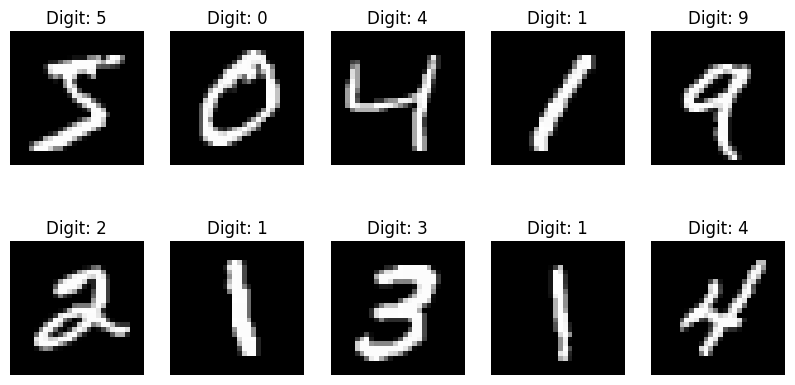

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(f"Digit: {y_train[i]}")
    plt.axis("off")

plt.show()

In [8]:
# Normalize pixel values
import numpy as np
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Add grayscale channel
X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (60000, 28, 28, 1, 1)
Testing shape: (10000, 28, 28, 1, 1)


In [9]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense

model=Sequential([
    Conv2D(32,(3,3), activation='relu', input_shape=(28,28,1)),
    MaxPooling2D(pool_size=(2,2)),
    Conv2D(64,(3,3), activation='relu'),
    MaxPooling2D(pool_size=(2,2)),
    Conv2D(64,(3,3), activation='relu'),
    MaxPooling2D(pool_size=(2,2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')

])
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 26, 26, 32)        320       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 13, 13, 32)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 11, 11, 64)        18496     
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 5, 5, 64)         0         
 2D)                                                             
                                                                 
 conv2d_2 (Conv2D)           (None, 3, 3, 64)          36928     
                                                                 
 max_pooling2d_2 (MaxPooling  (None, 1, 1, 64)         0

In [10]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [11]:
history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/50
844/844 [==============================] - 21s 7ms/step - loss: 1.3304 - accuracy: 0.5268 - val_loss: 0.4059 - val_accuracy: 0.8773
Epoch 2/50
844/844 [==============================] - 6s 8ms/step - loss: 0.3628 - accuracy: 0.8906 - val_loss: 0.2326 - val_accuracy: 0.9330
Epoch 3/50
844/844 [==============================] - 6s 7ms/step - loss: 0.2556 - accuracy: 0.9224 - val_loss: 0.1973 - val_accuracy: 0.9420
Epoch 4/50
844/844 [==============================] - 6s 7ms/step - loss: 0.2078 - accuracy: 0.9366 - val_loss: 0.1621 - val_accuracy: 0.9555
Epoch 5/50
844/844 [==============================] - 5s 6ms/step - loss: 0.1775 - accuracy: 0.9447 - val_loss: 0.1571 - val_accuracy: 0.9517
Epoch 6/50
844/844 [==============================] - 8s 10ms/step - loss: 0.1573 - accuracy: 0.9500 - val_loss: 0.1335 - val_accuracy: 0.9638
Epoch 7/50
844/844 [==============================] - 7s 8ms/step - loss: 0.1443 - accuracy: 0.9549 - val_loss: 0.1222 - val_accuracy: 0.9645
Epoc

In [12]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

313/313 [==============================] - 2s 4ms/step - loss: 0.0825 - accuracy: 0.9799  
Test Loss: 0.0825154259800911
Test Accuracy: 0.9799000024795532


In [13]:
model.save("../models/mnist_cnn.keras")
print("Model saved successfully!")

Model saved successfully!


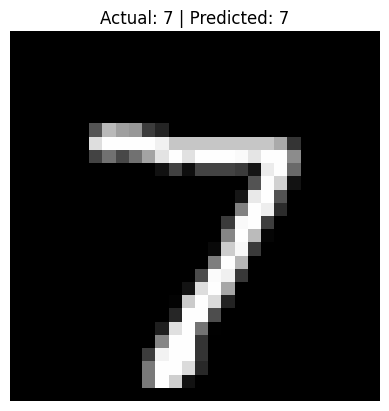

Actual digit: 7
Predicted digit: 7


In [14]:
import numpy as np
import matplotlib.pyplot as plt

# Select one test image
index = 0

image = X_test[index]
true_label = y_test[index]

# Make prediction
prediction = model.predict(image[np.newaxis, ...], verbose=0)

predicted_label = np.argmax(prediction)

# Display image
plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Actual: {true_label} | Predicted: {predicted_label}")
plt.axis("off")
plt.show()

print("Actual digit:", true_label)
print("Predicted digit:", predicted_label)

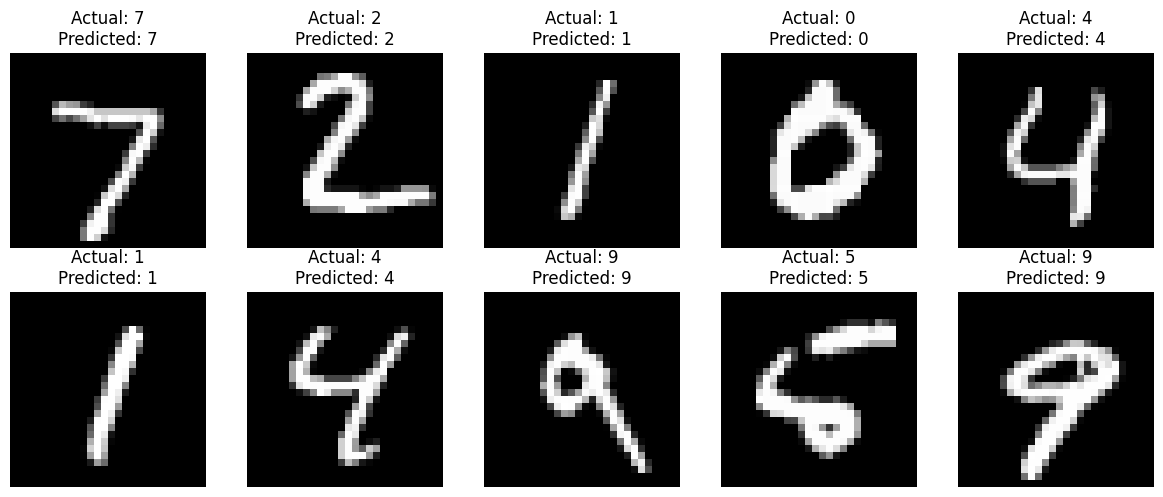

In [15]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

for i in range(10):

    image = X_test[i]

    prediction = model.predict(
        image[np.newaxis, ...],
        verbose=0
    )

    predicted_label = np.argmax(prediction)

    plt.subplot(2, 5, i + 1)
    plt.imshow(image.squeeze(), cmap="gray")
    plt.title(
        f"Actual: {y_test[i]}\nPredicted: {predicted_label}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()